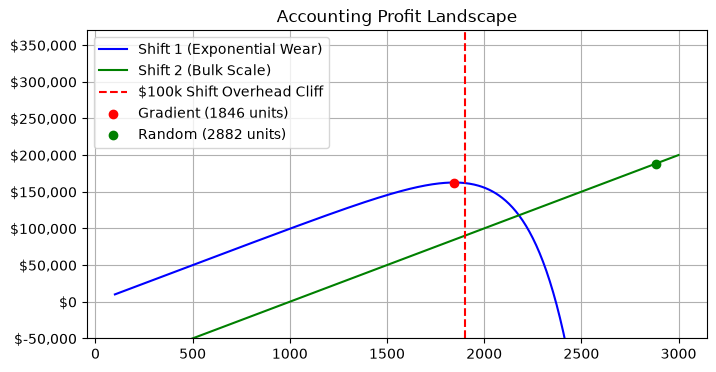

Gradient: 1,846 units | Profit: $162,565.92
Random:   2,882 units | Profit: $188,200.00


In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

min_allowed, max_allowed = 100, 3000
def calc_profit(u): return -((100*u - 5*np.exp(u/220)) if u <= 1900 else (100*u - 100000))

g_res = minimize(calc_profit, [1840.0], method='L-BFGS-B', bounds=[(min_allowed, max_allowed)])
r_x = np.random.randint(min_allowed, max_allowed + 1, 15)
r_best = r_x[np.argmin([calc_profit(g) for g in r_x])]
u_full = np.linspace(min_allowed, max_allowed, 500)

plt.figure(figsize=(8, 4))
plt.plot(u_full, [100*x - 5*np.exp(x/220) for x in u_full], 'b-', label='Shift 1 (Exponential Wear)')
plt.plot(u_full, [100*x - 100000 for x in u_full], 'g-', label='Shift 2 (Bulk Scale)')
plt.axvline(1900, color='r', linestyle='--', label='$100k Shift Overhead Cliff')
plt.scatter([g_res.x[0]], [-g_res.fun], color='red', zorder=5, label=f'Gradient ({g_res.x[0]:.0f} units)')
plt.scatter([r_best], [-calc_profit(r_best)], color='green', zorder=5, label=f'Random ({r_best:.0f} units)')
plt.ylim(-50000, 370000)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"${x:,.0f}"))
plt.title('Accounting Profit Landscape'); plt.grid(True); plt.legend(); 
plt.show()

print(f"Gradient: {g_res.x[0]:,.0f} units | Profit: ${-g_res.fun:,.2f}")
print(f"Random:   {r_best:,.0f} units | Profit: ${-calc_profit(r_best):,.2f}")